# FPM reconstruction with misalignment correction

One notebook for every dataset. Pick a directory under `data/` and a method;
everything else comes from that directory's `config.yaml` plus
`config_<method>.yaml` (keys it leaves out take the defaults listed in
`data/_template`, which reproduce the MATLAB code).

| method | what it does |
| --- | --- |
| `pie` | conventional FPM, LED array at its nominal position |
| `sa` | each LED's position annealed independently inside the iterations |
| `pcfpm` | per-LED annealing pulled back onto a rigid array |
| `mcfpm` | the paper's method: anneal the array shift with a whole reconstruction as the cost, then reconstruct |

Nothing here contains algorithm code: the physics and the solvers live in
`src/fpm`.

In [22]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root / 'src'))

from fpm import FPM, dataset_name, load_config, output_dir
from fpm.config import DATA_ROOT, iter_dataset_dirs

dataset_dir = project_root / 'data' / 'root' / 'middle_upper_left'
method = 'mcfpm'          # 'pie', 'sa', 'pcfpm' or 'mcfpm'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'cuda'

## Datasets

Every directory under `data/` with a `config.yaml`. The names say where the
segment lies on the sensor, as seen in the raw frames with row 0 at the top.
The last column says whether the dataset has its own settings file for the chosen
method.

In [23]:
for directory in iter_dataset_dirs(DATA_ROOT):
    config = load_config(directory, method)
    model_config = config.get('model') or {}
    x = model_config.get('sample_offset_x_mm', 0.0)
    y = model_config.get('sample_offset_y_mm', 0.0)
    settings = f'config_{method}.yaml' if config['config_paths']['method'] else 'defaults'
    print(f"{dataset_name(directory):28s} {config['data']['file']:30s} "
          f"patch (x, y) = ({x:+.4f}, {y:+.4f}) mm   {settings}")

root/center                  raw/20170531-3.mat             patch (x, y) = (+0.0000, +0.0000) mm   defaults
root/edge_upper_left         raw/20170531-3-700600.mat      patch (x, y) = (+0.9750, +1.1375) mm   defaults
root/edge_upper_right        raw/20170531-3-550-750.mat     patch (x, y) = (-1.2188, +0.8938) mm   defaults
root/inner_upper_left        raw/20170531-3-300200.mat      patch (x, y) = (+0.3250, +0.4875) mm   defaults
root/inner_upper_left_far    raw/20170531-3-300.mat         patch (x, y) = (+0.4875, +0.4875) mm   defaults
root/middle_upper_left       raw/20170531-3-500400.mat      patch (x, y) = (+0.6500, +0.8125) mm   defaults
usaf/center                  raw/20170604-3.mat             patch (x, y) = (+0.0000, +0.0000) mm   defaults
usaf/edge_upper_right        raw/20170604-1-400.mat         patch (x, y) = (+0.4875, +0.4875) mm   config_mcfpm.yaml


## Load the instrument

`from_directory` reads the configs, loads the measurements as intensity without
modifying the file on disk, and builds the LED geometry.

In [24]:
model = FPM.from_directory(dataset_dir, method=method, device=device)

print(model)
print(f'wavelength      {model.wavelength * 1e9:.1f} nm')
print(f'objective NA    {model.na}')
print(f'object pixel    {model.pixel_size_object / model.upscale * 1e6:.4f} um')
print(f'LED array       {model.array_size} x {model.array_size}, {model.led_pitch_mm} mm pitch, '
      f'{model.led_height_mm} mm below the sample')
print(f'{model.size_lr} px  ->  {model.size_hr} px  (upscale {model.upscale})')
print(f'patch offset    x = {model.sample_offset_mm[0]:+.4f} mm, y = {model.sample_offset_mm[1]:+.4f} mm')
model.recon

FPM(dataset='middle_upper_left', method='mcfpm', frames=289, size=128->512, device=cuda)
wavelength      629.7 nm
objective NA    0.1
object pixel    0.4062 um
LED array       17 x 17, 4.0 mm pitch, 113.5 mm below the sample
128 px  ->  512 px  (upscale 4)
patch offset    x = +0.6500 mm, y = +0.8125 mm


{'upscale': 4, 'alpha': 1.0, 'beta': 1.0, 'seed': 0, 'print_every': 10}

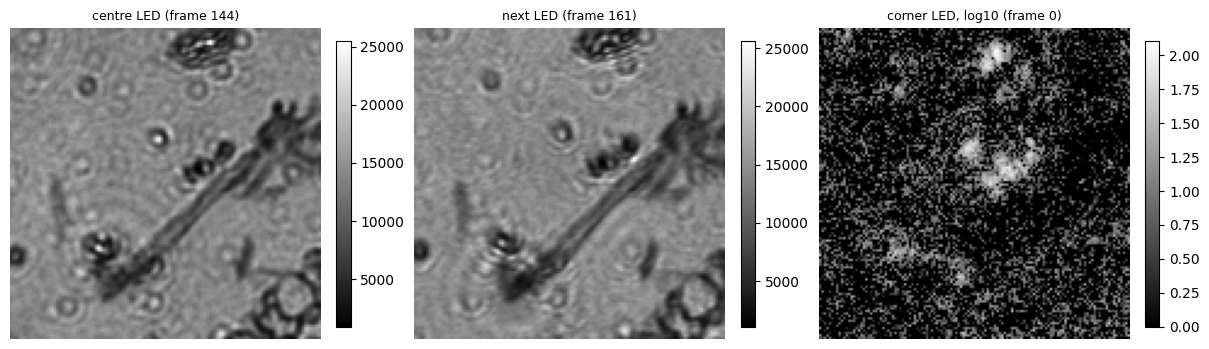

In [25]:
# A quick look at the raw stack before solving anything: the centre LED, the
# next one in the spiral, and a corner LED far into dark field (log scale).
frames = {
    'centre LED': model.centre_frame,
    'next LED': int(model.scan_order[1]),
    'corner LED, log10': 0,
}
figure, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for ax, (title, index) in zip(axes, frames.items()):
    frame = model.intensity[index].cpu().numpy()
    if 'log' in title:
        frame = np.log10(frame + 1)
    image = ax.imshow(frame, cmap='gray')
    ax.set_title(f'{title} (frame {index})', fontsize=9)
    ax.set_axis_off()
    figure.colorbar(image, ax=ax, fraction=0.046)
plt.show()

## Settings

The method config decides everything. To try a setting without editing the
YAML, put it in `overrides`: the keys and what they mean are listed in
`data/_template/config_<method>.yaml`, the saved metadata records what was
used, and a result with overrides is saved beside the configured one rather
than replacing it.

`mcfpm` with `main.m`'s settings takes about five minutes on a laptop GPU; the
paper's mcFPM I (`coarse_array_size: 5`, `coarse_iterations: 5`) well under a
minute. `upscale` cannot be changed here: it fixes the object size when the
model is built.

In [26]:
overrides = {}
# overrides = {'coarse_array_size': 5, 'coarse_iterations': 5}   # mcFPM I
# overrides = {'coarse_cost': 'intensity'}                        # Eq. 15 of the paper as the cost
# overrides = {'fine_iterations': 10}                             # mcFPM III: per-LED search after the pose

if 'upscale' in overrides:
    raise ValueError('upscale sets the object size; change it in the YAML file instead')
model.recon.update(overrides)

## Reconstruct

`run()` dispatches to the solver named by `method`; `model.pie()`,
`model.mcfpm()` and the others can also be called directly.

In [27]:
started = time.perf_counter()
result = model.run()
print(f'{method} took {time.perf_counter() - started:.1f} s')

print(f'object   {tuple(result.object.shape)}  {result.object.dtype}')
print(f'loss     {result.loss[0]:.4g}  ->  {result.loss[-1]:.4g}   (intensity misfit, first and last sweep)')
if result.led_pose is not None:
    x, y, rotation, height = result.led_pose
    print(f'LED pose shift x = {x:+.3f} mm, y = {y:+.3f} mm, rotation {rotation:+.3f} deg, height {height:.2f} mm')

mcfpm anneal 10: cost 7.60325e+09, pose [  0.    0.    0.  113.5] (42 s)
mcfpm anneal 20: cost 7.59839e+09, pose [ -1.1117  -1.2396   0.     113.5   ] (79 s)
mcfpm anneal 30: cost 7.59839e+09, pose [ -1.1117  -1.2396   0.     113.5   ] (120 s)
mcfpm anneal 40: cost 7.59839e+09, pose [ -1.1117  -1.2396   0.     113.5   ] (174 s)
mcfpm anneal 50: cost 7.59697e+09, pose [ -0.6481  -1.4987   0.     113.5   ] (211 s)
mcfpm anneal 60: cost 7.59697e+09, pose [ -0.6481  -1.4987   0.     113.5   ] (250 s)
mcfpm anneal 70: cost 7.59658e+09, pose [ -0.4819  -1.5472   0.     113.5   ] (284 s)
mcfpm anneal 80: cost 7.59658e+09, pose [ -0.4819  -1.5472   0.     113.5   ] (324 s)
mcfpm anneal 90: cost 7.59658e+09, pose [ -0.4819  -1.5472   0.     113.5   ] (364 s)
mcfpm anneal 100: cost 7.59658e+09, pose [ -0.4819  -1.5472   0.     113.5   ] (406 s)
mcfpm took 406.6 s
object   (512, 512)  torch.complex128
loss     3.29e+13  ->  1.021e+13   (intensity misfit, first and last sweep)
LED pose shift x = -

## Inspect

The summary shows the centre frame, the reconstructed amplitude and phase, the
object spectrum, the pupil, where the LED windows ended up (nominal in black,
corrected in red), and the annealing cost or the misfit of every sweep.

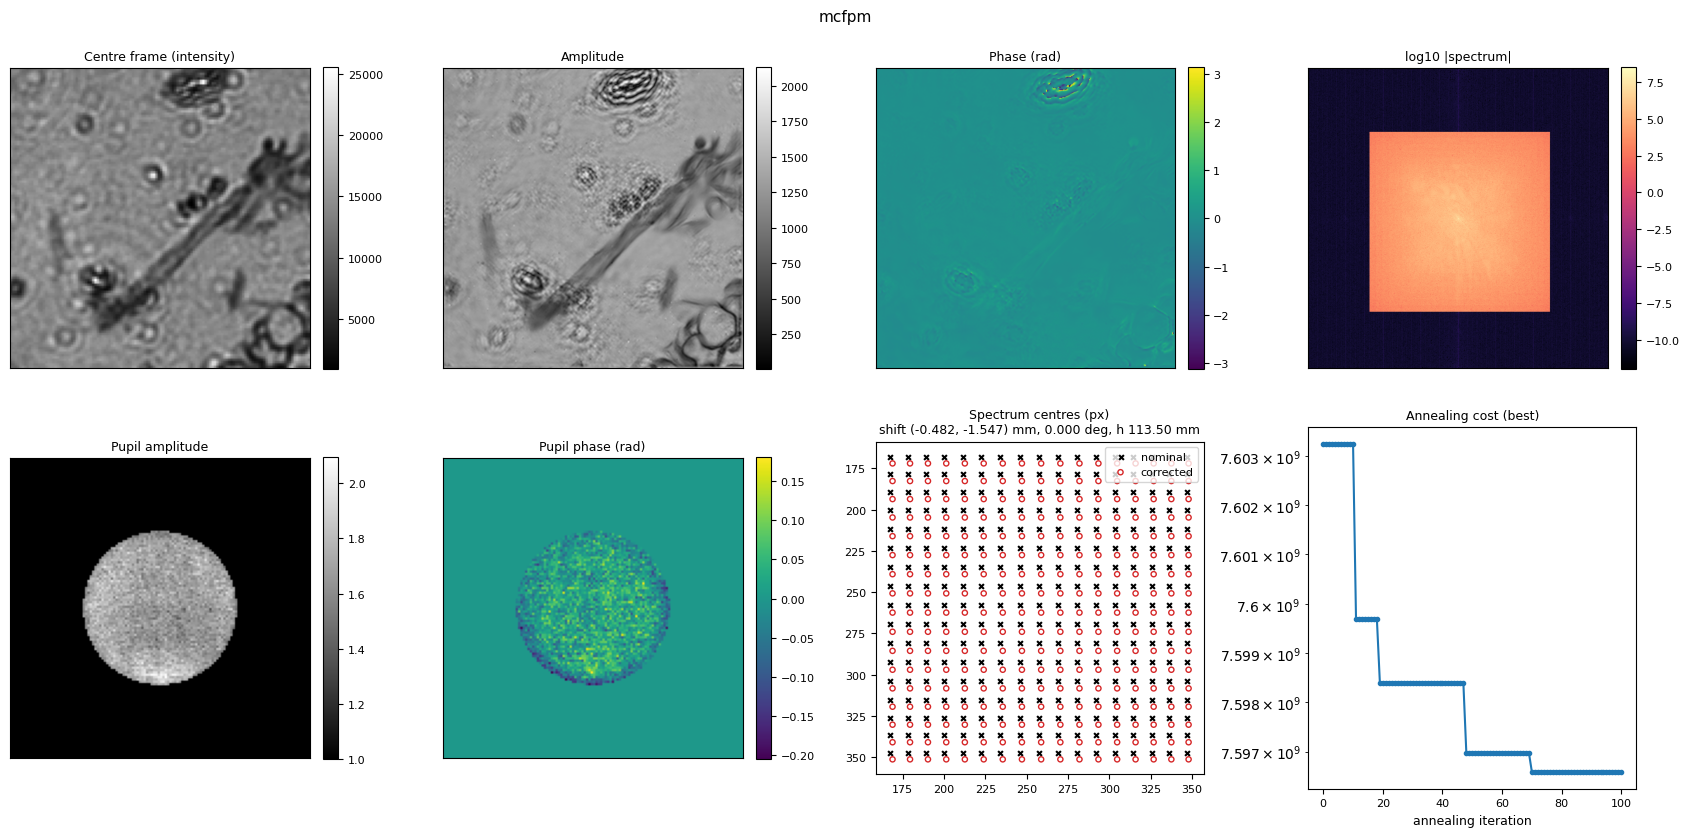

In [28]:
figure = model.summary_figure()
plt.show()

## Compare with conventional FPM

The same dataset reconstructed by `pie`: loaded from `notebooks/output` when it
has been saved there (for instance by `tools/run_all.py`), otherwise
reconstructed here in a few seconds.

pie: loaded notebooks\output\root\middle_upper_left\pie\reconstruction.npz


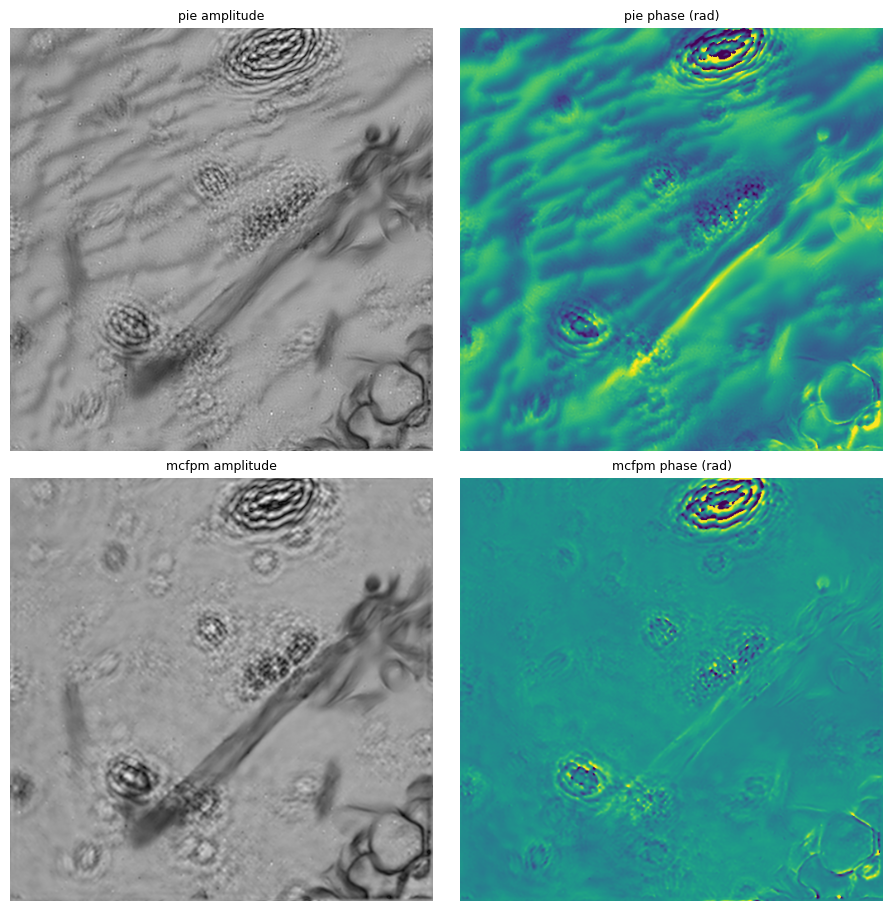

In [29]:
def amplitude_and_phase(object_field):
    field = np.asarray(object_field)
    field = field * np.exp(-1j * np.angle(field.mean()))   # the absolute phase is not measurable
    return np.abs(field), np.angle(field)


saved = output_dir(dataset_dir, 'pie') / 'reconstruction.npz'
if saved.is_file():
    with np.load(saved) as arrays:
        baseline = arrays['object']
    print(f'pie: loaded {saved.relative_to(project_root)}')
else:
    baseline = FPM.from_directory(dataset_dir, 'pie', device=device).run().object.numpy()
    print('pie: reconstructed here')

figure, axes = plt.subplots(2, 2, figsize=(9, 9), constrained_layout=True)
for row, (name, field) in enumerate([('pie', baseline), (method, result.object.numpy())]):
    amplitude, phase = amplitude_and_phase(field)
    limit = max(np.percentile(np.abs(phase), 99.5), 0.05)
    axes[row, 0].imshow(amplitude, cmap='gray')
    axes[row, 1].imshow(phase, cmap='viridis', vmin=-limit, vmax=limit)
    axes[row, 0].set_title(f'{name} amplitude', fontsize=9)
    axes[row, 1].set_title(f'{name} phase (rad)', fontsize=9)
for ax in axes.ravel():
    ax.set_axis_off()
plt.show()

## Save

Writes `reconstruction.npz`, `metadata.json` and `summary.png` to
`notebooks/output/<dataset>/<method>/`, or to `<method>_custom/` beside it when
`overrides` is not empty. The metadata records which files and settings
produced the result.

In [30]:
target = output_dir(dataset_dir, method)
if overrides:
    target = target.with_name(f'{method}_custom')
out_dir = result.save(target, model=model, summary=True)
print(out_dir.relative_to(project_root))
sorted(p.name for p in out_dir.iterdir())

notebooks\output\root\middle_upper_left\mcfpm


['metadata.json', 'reconstruction.npz', 'summary.png']

## Run all

`tools/run_all.py` does for every dataset what the cells above did for one, and
`tools/summarize_results.py` puts the saved results side by side, one row per
dataset. On a laptop GPU, `pie` over all eight datasets takes about half a
minute and `mcfpm` with `main.m`'s settings about 40 minutes, so the batch only
runs when `run_everything` is set; the comparison is drawn from whatever has
been saved.

In [31]:
# sys.path.insert(0, str(project_root / 'tools'))
# import run_all
# import summarize_results

# run_everything = False          # True reconstructs every selected dataset first
# methods = ['pie', 'mcfpm']
# only = []                       # e.g. ['usaf', 'root/edge_upper_left']; empty = every dataset

# if run_everything:
#     args = ['--methods', *methods, '--device', device]
#     if only:
#         args += ['--only', *only]
#     run_all.main(args)

# figure = summarize_results.main(['--methods', *methods])
# plt.show()